# Setup
If you have not run the below code in a separate Julia session, this notebook will not work.
```
using Pkg
Pkg.add("DrWatson")          
Pkg.activate("path/to/temp-tune")
Pkg.instantiate()

cd("path/to/temp-tune")
include(scriptsdir("setup_python.jl"))
```

## activate project

In [2]:
using Pkg
using DrWatson
@quickactivate "temp-tune"
println("current active project = ",Base.active_project())

current active project = /Users/pfields/Git/temp-tune/Project.toml


## setup plotting

In [3]:
include(srcdir("matplotlib_helpers.jl"))
setup_notebook_for_paper()
using_Py(true)

setup_rc_reset()
set_plot_style_for_paper(; venue="revtex")

Plot style set → venue=revtex, font='Arial'
Sizes (pt): label=10.0  tick=8.0  legend=8.0  mathtext.fontset=cm
Python     : /Users/pfields/Git/temp-tune/.conda/bin/python
Matplotlib : 3.10.8 | backend=Agg
 set plot style finished. exiting...



## other packages

In [60]:
using StatsBase, Statistics, LinearAlgebra, Printf, Random
using SpecialFunctions
using Parameters, Flux
using Optim, BenchmarkTools, JLD2, DataFrames, Graphs
using OptimizationOptimJL, Optimization
using Roots, Expectations
using Distributions
using Conda
using Dierckx
using CUDA
using SpinModels

In [61]:
include(srcdir("sweep_nn_ising.jl"))
include(srcdir("nearest_neighbor_ising.jl"))
include(srcdir("samplers.jl"))

drawsamples!! (generic function with 3 methods)

# Run experiments on 3 by 3 ising model at different T, M

In [6]:
nreps = 10
true_temps_to_sweep=collect(2.00:0.1:3.5)

mu_vals_to_sweep = [] # mu = log( M / e^H_true ) -- an entropy normalized sample number. 
# leave as empty array if not in use

nsamples_to_sweep = Int.(round.(10 .^collect(range(;start=log10(50), stop=log10(1500), length=10))))

10-element Vector{Int64}:
   50
   73
  106
  155
  227
  331
  483
  704
 1028
 1500

In [7]:
tau_sweep_opts_3by3 = TauSweepOptions(
    nreps, mu_vals_to_sweep, 
    true_temps_to_sweep, "constant M", m_by_n=(3,3), 
    nsamples_to_sweep = nsamples_to_sweep );

In [8]:
savedir=datadir("ising_sweeps","constant_M_3by3")
mkpath(savedir)

"/Users/pfields/Git/temp-tune/data/ising_sweeps/constant_M_3by3"

In [56]:
run_full_sweeps_exact( tau_sweep_opts_3by3, 
                        savedir, keep_buffer=false )

nsampless = [50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0]

rep = 1

TIME ELAPSED = 0 min

 RUNNING SWEEPS FOR N TRAINING SAMPLES = 50.0
getting samples at T=2.0
done!

 fitting model to data taken at T=2.0
iter = 0, -likelihood = 15.82331236424216
   logZ=[15.415544142674467]
   mean energy of train data = [0.4077682215676939]
iter = 1000, -likelihood = 1.8172218693113376
   logZ=[13.374468920307656]
   mean energy of train data = [-11.557247050996319]
iter = 2000, -likelihood = 1.772499488671258
   logZ=[14.050330460035632]
   mean energy of train data = [-12.277830971364374]
iter = 2412, -likelihood = 1.7639310529610697
relTol of 1.0e-5 reached



 getting samples from fit model on samples taken at T=2.000000 
sweeping fit model tau from 0.2 to 5.0
done!

rep = 2

TIME ELAPSED = 0 min

 RUNNING SWEEPS FOR N TRAINING SAMPLES = 50.0
getting samples at T=2.0
done!

 fitting model to data taken at T=2.0
iter = 0, -likelihood = 10.79117873714716
   logZ=[11.356332467472937]

Excessive output truncated after 524299 bytes.

iter = 1000, -likelihood = 3.606901132160992
   logZ=[8.43835812497198]
   mean energy of train data = [-4.831456992810988]
iter = 1503, -likelihood = 3.573918420564051
relTol of 1.0e-5 reached



 getting samples from fit model on samples taken at T=2.700000 
sweeping fit model tau from 0.2 to 5.0
done!

rep = 6

TIME ELAPSED = 1 min

 RUNNING SWEEPS FOR N TRAINING SAMPLES = 331.0
getting samples at T=2.7
done!

 fitting model to data taken at T=2.7
iter = 0, -likelihood = 14.600875831330178
   logZ=[13.80191309964711]
   mean energy of train data = [0.7989627316830673]
iter = 1000, -likelihood = 3.681434990961419

# make tau sweep plots for one experiment

### plot funcs

In [128]:
function plot_one_ising_replicate(ax, df_raw_all_reps, M, T, r, J_gt, ml_bf, e_bf; leg3_loc=(0.16,0.535))
    sss="indianred"
    coral_rgba=(matplotlib.colors.to_rgba(sss)[1:3]..., 0.5)
    coral_rgb1=matplotlib.colors.to_rgba(sss)
    steelblue_rgba=(matplotlib.colors.to_rgba("steelblue")[1:3]...,0.5)
    steelblue_rgba1=(matplotlib.colors.to_rgba("steelblue")[1:3]...,1)

    temp_filt(t,m) = all( (t,m).== (T,M) )
    df_filtered = filter( [:T, :M] => temp_filt, df_raw_all_reps );  

    J_fitt = df_filtered.J_fit[][r, :,:]

    τ_swept = df_filtered.tau_swept[]           

    all_e_dict, avg_prob_per_e_level, rel_surprise_per_e_level, rel_surpise =decompose_dkls_ising( 
                                                                    J_gt, J_fitt, ml_bf, e_bf, T );

    idcss=2:all_e_dict[:n_levels]
    xxss = collect(1:all_e_dict[:n_levels])
    # ax[1].bar( xxss , avg_prob_per_e_level[:gt].-avg_prob_per_e_level[:fit] )


    ggss = all_e_dict[:nstates_per_level][idcss]

    ax[1].bar( xxss[idcss] , all_e_dict[:nstates_per_level][idcss] , width=0.5, color="k" )
    ax[1].set_yscale("log")


    ax[2].bar(xxss[idcss].-0.135 , avg_prob_per_e_level[:gt][idcss], 
        width=0.25, color=(0,0,0,0.5),edgecolor="k", #hatch="......",
          linewidth=0.6,
        label=L"p_{T,i}")

    ax[2].bar(xxss[idcss].+0.135 , avg_prob_per_e_level[:fit][idcss] , 
        width=0.25, color=(0,0,0,0.1),edgecolor="k", #hatch="///////",
        linewidth=0.6,
     label=L"\hat{q}_{i}")

    ax[2].set_yscale("log")

    br=ax[3].bar( xxss[idcss].-0.19 , rel_surpise[:gt][idcss], width=0.25, 
            edgecolor=coral_rgb1, facecolor=coral_rgba,
                    label=L"D_{KL}(p_T || \hat q)\cap\Lambda_i", hatch="\\\\",
            rasterized = true)
    bb=ax[3].bar( xxss[idcss].+0.19 , rel_surpise[:fit][idcss] , width=0.25, 
        ec=steelblue_rgba1, facecolor=steelblue_rgba,
                    label=L"D_{KL}(\hat q||p_T)\cap\Lambda_i", hatch="\\\\" ,
        rasterized = true);
    for l in 1:length(bb)
        bb[l]._hatch_color, br[l]._hatch_color = ntuple(i->matplotlib.colors.to_rgba("white"),2)
    end

    ax[2].legend(frameon=false, 
        # fontsize=18, 
        framealpha=1,
        handlelength=1.33, handletextpad=0.2,
        labelspacing=0.2, loc=(0.64, 0.55))

    ax[3].set_xticks(xxss[idcss])
    ax[3].set_xticklabels(collect(idcss).-1)
    

    leg3 = ax[3].legend(frameon=false, 
        # fontsize=15, 
        loc=leg3_loc,
        # bbox_to_anchor=(0.475, 0.66), 
        handlelength=1.33, handletextpad=0.2,
        labelspacing=0.2)

    leg3_ = ax[3].get_legend()

    ax[1].set_ylabel("density\nof states")
        # labelpad=50)?

    ax[2].set_ylabel("average prob.\nmass per state")
    ax[3].set_xlabel("energy level index")
    
end


plot_one_ising_replicate (generic function with 2 methods)

In [129]:
function plot_tau_sweep_one_rep(ax, df_raw_all_reps, M, T, r, J_gt, ml_bf, e_bf;
                                    mss=5, lww=1, leg1_loc=(0.289,0.54),
                                    leg3_loc=(-0.02,0.44), exct_idx=3 )
    
    ax[2], ax[3] = (ax[3], ax[2])

    sss="indianred"
    coral_rgba=(matplotlib.colors.to_rgba(sss)[1:3]..., 0.5)
    coral_rgb1=matplotlib.colors.to_rgba(sss)
    steelblue_rgba=(matplotlib.colors.to_rgba("steelblue")[1:3]...,0.5)
    steelblue_rgba1=(matplotlib.colors.to_rgba("steelblue")[1:3]...,1)

    temp_filt(t,m) = all( (t,m).== (T,M) )
    df_filtered = filter( [:T, :M] => temp_filt, df_raw_all_reps );  

    J_fitt = df_filtered.J_fit[][r, :,:]
    
    τ_swept = df_filtered.tau_swept[]

    all_e_dict_tau1, _, _, _ = decompose_dkls_ising( 
                                                    J_gt, J_fitt, ml_bf, e_bf, T );

    suprise_per_level_of_tau = Dict( :gt=>zeros( all_e_dict_tau1[:n_levels], length(τ_swept) ),
                                    :fit=>zeros( all_e_dict_tau1[:n_levels], length(τ_swept) ))

    for (kk,ττ) in enumerate(τ_swept)
        all_e_dict, _, _, rel_surpise = decompose_dkls_ising( 
                                                         J_gt, J_fitt./ττ, ml_bf, e_bf, T );

        suprise_per_level_of_tau[:gt][:, kk] .= rel_surpise[:gt]
        suprise_per_level_of_tau[:fit][:, kk] .= rel_surpise[:fit]
    end 

    tau_star = τ_swept[findmin( vec(sum( suprise_per_level_of_tau[:fit][1:end,:],dims=1 ) ) )[2]]
    tau_prime = τ_swept[findmin( vec(sum( suprise_per_level_of_tau[:gt][1:end,:],dims=1 ) ) )[2]]


    ax[1].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:gt][1:end,:],dims=1 ) ) ,
                color=coral_rgb1, label=L"D_{KL}(p_T || \hat q_\tau)",
                linewidth=lww)
    ax[1].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:fit][1:end,:],dims=1 ) ),  
                color=steelblue_rgba1,label=L"D_{KL}(\hat q_\tau||p_T)"  ,
                linewidth=lww)
    # ax[1].grid("on", alpha=0.35)
    ax[1].vlines( 1, -1,5, color="k", alpha=0.05,
                linewidth=lww)
    ax[2].vlines( 1, -1,5, color="k", alpha=0.05,
                linewidth=lww)
    ax[3].vlines( 1, -1,5, color="k", alpha=0.05,
                linewidth=lww)
    ax[1].vlines( (tau_star,tau_prime), -1,5, color="k", alpha=0.15,
                linewidth=lww)
    ax[1].plot( [tau_star,tau_prime], [
            findmin( vec(sum( suprise_per_level_of_tau[:fit][1:end,:],dims=1) ) )[1]
            findmin( vec(sum( suprise_per_level_of_tau[:gt][1:end,:],dims=1 ) ) )[1] ],
            "k.", markersize=mss)

    ax[1].legend(loc=leg1_loc, 
        # fontsize=18, 
        framealpha=1, frameon=false, 
        # bbox_to_anchor=(1.025, -0.065),
        labelspacing=0.2, handletextpad=0.1, handlelength=1)

    ax[2].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:gt][1:end,:],dims=1 ) ) ,
                color=coral_rgb1, alpha=0.5,
                linewidth=lww)
    
    
    ax[2].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:gt][1:1,:],dims=1 ) ),
                linestyle="dotted", color="k", label="ground",
                linewidth=lww)
    
    ax[2].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:gt][2:(exct_idx+1),:],dims=1 ) ),
                linestyle="dashed", color="k", label="excited 1 to $exct_idx",
                linewidth=lww)
    ax[2].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:gt][(exct_idx+2):end,:],dims=1 ) ),
                linestyle="solid", color="k",label="excited $(exct_idx+1) and up",
                linewidth=lww)
    # ax[2].grid("on", alpha=0.2)
    ax[2].vlines( (tau_star,tau_prime), -1,5, color="k", alpha=0.15, linewidth=lww)
      ax[2].plot( [tau_star,tau_prime][2], [
            findmin( vec(sum( suprise_per_level_of_tau[:fit][1:end,:],dims=1) ) )[1]
            findmin( vec(sum( suprise_per_level_of_tau[:gt][1:end,:],dims=1 ) ) )[1] ][2],
            "k.", markersize=mss)
    # ax[2].legend(framealpha=1, loc="upper right", frameon=false)



    ax[3].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:fit][1:end,:],dims=1 ) ) ,
                color=steelblue_rgba1, alpha=0.5,
                linewidth=lww)
    ax[3].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:fit][1:1,:],dims=1 ) ),
                linestyle="dotted", color="k", label="ground",
                linewidth=lww)
    ax[3].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:fit][2:(exct_idx+1),:],dims=1 ) ),
                linestyle="dashed", color="k", label="excited 1 to $exct_idx",
                linewidth=lww)
    ax[3].plot( τ_swept, vec(sum( suprise_per_level_of_tau[:fit][(exct_idx+2):end,:],dims=1 ) ),
                linestyle="solid", color="k", label="excited $(exct_idx+1) and up",
                linewidth=lww)
    ax[3].legend(framealpha=1, loc=leg3_loc, 
        frameon=false, handletextpad=0.2,
        # fontsize=15, 
        handlelength=1, labelspacing=0.1)
    # ax[3].legend()

    # ax[3].grid("on", alpha=0.35)
    ax[3].vlines( (tau_star,tau_prime), -1,5, color="k", alpha=0.15, linewidth=lww)
    ax[3].plot( [tau_star,tau_prime][1], [
            findmin( vec(sum( suprise_per_level_of_tau[:fit][1:end,:],dims=1) ) )[1]
            findmin( vec(sum( suprise_per_level_of_tau[:gt][1:end,:],dims=1 ) ) )[1] ][1],
            "k.", markersize=mss)
    
    for k in [1,3]
    ax[k].tick_params(labelbottom=false)
    end
    
    ax[1].set_ylabel("nats")
    # , fontsize=13)
    ax[2].set_ylabel(L"D_{KL}"*" per level")
        # , fontsize=13)
    ax[3].set_ylabel(L"D_{KL}"*" per level")

    ax[1].set_xlim(0.5,1.4)
    ax[1].set_ylim(-0.25,3.25)
    
end

plot_tau_sweep_one_rep (generic function with 1 method)

### import sweeps
`tau_sweep_opts_3by3` and `savedir` used to load sweeps

In [135]:
df_raw_all_reps = DataFrame() 


# append!( df_raw_all_reps, load_from_sweeps( tau_sweep_opts_low, savedir_low ) )
# append!( df_raw_all_reps, load_from_sweeps( tau_sweep_opts_low_2, savedir_low ) )
# append!( df_raw_all_reps, load_from_sweeps( tau_sweep_opts_high, savedir_high ) )
# append!( df_raw_all_reps, load_from_sweeps( tau_sweep_opts_high_2, savedir_high ) )
# append!( df_raw_all_reps, load_from_sweeps( tau_sweep_opts_old, savedir_old ) )

append!( df_raw_all_reps, load_from_sweeps( tau_sweep_opts_3by3, savedir ) );

In [134]:
# unique(df_raw_all_reps.T)

### break down dkl at tau=1

In [130]:
#which sim to plot
M, T, r = (50.0, 2., 3) # number training data, ground truth temp, replicate index

(50.0, 2.0, 3)

In [85]:
_, J_gt = init_2dNN(tau_sweep_opts_3by3.m_by_n...)
ml_bf = ExactMLBuffer(J_gt);
e_bf = Energy2spinBuffer(ml_bf.all_states, J_gt);

set_plot_style_for_paper(tick_pt=10., legend_pt=10., label_pt=10.)

Plot style set → venue=revtex, font='Arial'
Sizes (pt): label=10.0  tick=10.0  legend=10.0  mathtext.fontset=cm
Python     : /Users/pfields/Git/temp-tune/.conda/bin/python
Matplotlib : 3.10.8 | backend=Agg
 set plot style finished. exiting...



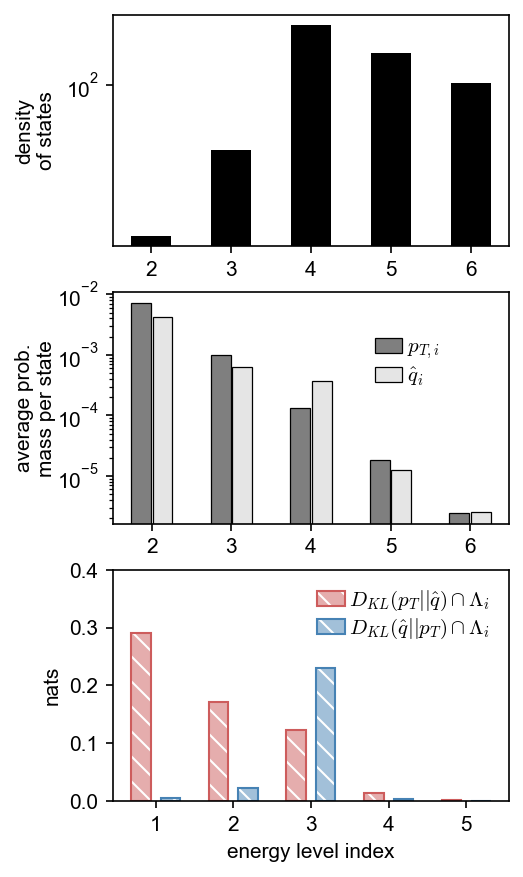

(0.0, 0.4)

In [131]:
fig, ax = subplots(3,1, figsize=set_size_for_paper(1, 2.,), dpi=150)


plot_one_ising_replicate(ax, df_raw_all_reps, M, T, r, J_gt, ml_bf, e_bf;
                            leg3_loc="upper right")

ax[2].yaxis.labelpad = 0.5
ax[1].yaxis.labelpad = 4.5
ax[3].set_ylabel("nats")#, labelpad=6)

ax[1].minorticks_off()

ax[3].set_ylim(0,0.4)

# ffnname="/Users/pfields/Documents/Inkscape/fig3-raw-new_T=$(T)_M=$(M)_r=$(r).svg"

# savefig(ffnname, dpi=600)


### sweep over sampling temp tau and track dkls

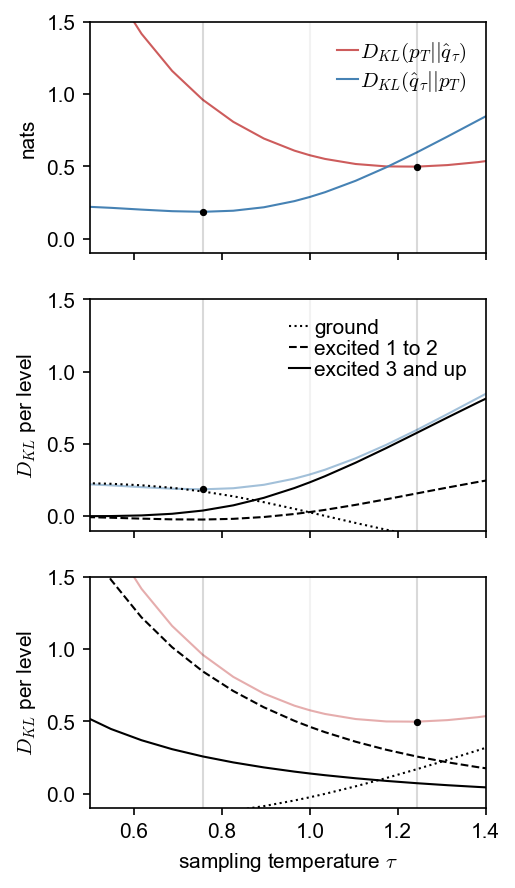

(-0.1, 1.5)

In [133]:
fig, ax = subplots(3,1, figsize=set_size_for_paper(1,2.), dpi=150)


plot_tau_sweep_one_rep(ax, df_raw_all_reps, M, T, r, J_gt, ml_bf, e_bf;
                                    mss=5, lww=1, 
                                    leg3_loc="upper right", 
                                    leg1_loc="upper right",
                                    exct_idx=2)

ax[2].set_xlabel("sampling temperature "*L"\tau")

# ax[1].yaxis.labelpad = 3
# ax[2].yaxis.labelpad = 3
# ax[3].yaxis.labelpad = 3

ax[2].sharey(ax[1])
ax[3].sharey(ax[1])
ax[2].sharex(ax[1])
ax[3].sharex(ax[1])

ax[1].set_ylim(-0.1,1.5)

In [ ]:
fig = plt.figure(figsize=set_size_for_paper(2, 4.6/14), dpi=500)

# Explicit positions as fractions of the figure: left < middle < right
#               left   right  bottom  top
gs_left_up   = fig.add_gridspec(1, 1, left=0.05, right=0.15, bottom=0.55, top=1.)
# gs_left_down = fig.add_gridspec(1, 3, left=0.05, right=0.57, bottom=0.0, top=.35, wspace=0.5)

gs_mid   = fig.add_gridspec(3, 2, left=0.34, right=0.76, bottom=0., top=1., 
    hspace=.15, wspace=0.5)
gs_right = fig.add_gridspec(2, 1, left=0.85, right=1., bottom=0., top=1., hspace=0.25)


ax_a = fig.add_subplot(gs_left_up[0,0]);

# ax_a11 = fig.add_subplot(gs_left_up[0]); 
ax_a21 = fig.add_subplot(gs_mid[0,1]); 

ax_a22 = fig.add_subplot(gs_mid[1,1]); #ax_a22.set_title("LEFT 2×2 (2,2)")
ax_a23 = fig.add_subplot(gs_mid[2,1]); 

# Middle block: 3 equal rows
ax_b1 = fig.add_subplot(gs_mid[0, 0])
ax_b2 = fig.add_subplot(gs_mid[1, 0])
ax_b3 = fig.add_subplot(gs_mid[2, 0])

# Right block: 2 equal rows
ax_c2 = fig.add_subplot(gs_right[0, 0]); 
ax_c1 = fig.add_subplot(gs_right[1, 0]); 


ax=[ax_a22, ax_a23, ax_a21, ax_b2, ax_b3, ax_b1 ]

In [ ]:


# ax_c1.set_xticks(())
# ax_c2.set_xticks(())

im22=tau_star_plots(ax_c2, mycmap, normmm)

# ax_c1.tick_params(labelbottom=false)
ax_c1.set_xlabel(" ")

# ax_c2.tick_params(labelbottom=false)
# ax_c2.set_xlabel("")

im11=tau_prime_plot(ax_c1, mycmap, normmm)

# ax_c1.set_aspect(1)
# ax_c2.set_aspect(1)


cb=colorbar(im22, ax=[ax_c1,ax_c2],orientation="horizontal", location="top",
        ticks=[0.5, 0.6, 0.7, 0.8, 0.9, 1., 2, 3])
cb.set_ticklabels([".5", ".6", ".7", ".8", ".9", "1", "2", "3"]) # custom text


ax_c2.yaxis.labelpad = 3
ax_c1.yaxis.labelpad = 3

ax_c1.text(275,3.6, "mean "*L"\tau'")
ax_c2.text(275,3.6, "mean "*L"\tau^*")

ax_c1.tick_params(labelbottom=false)
ax_c1.set_xlabel(" ")

ax_c2.tick_params(axis="x", pad=0.5)
ax_c1.set_yticks(collect(2:0.5:3.5))
ax_c2.set_yticks(collect(2:0.5:3.5))


In [ ]:
M, T, r = (71.0, 2.05, 4)

gridspec=matplotlib.gridspec
            
temp_filt(t,m) = all( (t,m).== (T,M) )
df_filtered = filter( [:T, :M] => temp_filt, df_raw_all_reps );            
# df_filtered = filter( [:T, :M] => temp_filt, df_raw_all_reps );

J_fitt = df_filtered.J_fit[][r, :,:]

τ_swept = df_filtered.tau_swept[]

all_e_dict_tau1, _, _, _ = decompose_dkls_ising( 
                                                J_gt, J_fitt, ml_bf, e_bf, T );

suprise_per_level_of_tau = Dict( :gt=>zeros( all_e_dict_tau1[:n_levels], length(τ_swept) ),
                                :fit=>zeros( all_e_dict_tau1[:n_levels], length(τ_swept) ))

for (kk,ττ) in enumerate(τ_swept)
    all_e_dict, _, _, rel_surpise = decompose_dkls_ising( 
                                                     J_gt, J_fitt./ττ, ml_bf, e_bf, T );
    
    suprise_per_level_of_tau[:gt][:, kk] .= rel_surpise[:gt]
    suprise_per_level_of_tau[:fit][:, kk] .= rel_surpise[:fit]
end            


fig = plt.figure(figsize=set_size_for_paper(2, 4.6/14), dpi=500)

# Explicit positions as fractions of the figure: left < middle < right
#               left   right  bottom  top
gs_left_up   = fig.add_gridspec(1, 1, left=0.05, right=0.15, bottom=0.55, top=1.)
# gs_left_down = fig.add_gridspec(1, 3, left=0.05, right=0.57, bottom=0.0, top=.35, wspace=0.5)

gs_mid   = fig.add_gridspec(3, 2, left=0.34, right=0.76, bottom=0., top=1., 
    hspace=.15, wspace=0.5)
gs_right = fig.add_gridspec(2, 1, left=0.85, right=1., bottom=0., top=1., hspace=0.25)


ax_a = fig.add_subplot(gs_left_up[0,0]);

# ax_a11 = fig.add_subplot(gs_left_up[0]); 
ax_a21 = fig.add_subplot(gs_mid[0,1]); 

ax_a22 = fig.add_subplot(gs_mid[1,1]); #ax_a22.set_title("LEFT 2×2 (2,2)")
ax_a23 = fig.add_subplot(gs_mid[2,1]); 

# Middle block: 3 equal rows
ax_b1 = fig.add_subplot(gs_mid[0, 0])
ax_b2 = fig.add_subplot(gs_mid[1, 0])
ax_b3 = fig.add_subplot(gs_mid[2, 0])

# Right block: 2 equal rows
ax_c2 = fig.add_subplot(gs_right[0, 0]); 
ax_c1 = fig.add_subplot(gs_right[1, 0]); 


ax=[ax_a22, ax_a23, ax_a21, ax_b2, ax_b3, ax_b1 ]



# J_fitt = df_filtered.J_fit[][r, :,:]

all_e_dict, avg_prob_per_e_level, rel_surprise_per_e_level, rel_surpise =decompose_dkls_ising( 
                                                                J_gt, J_fitt, ml_bf, e_bf, T );

# opt tau phase plots

# import sims from paper

In [ ]:
nreps = 10
nsamples_to_sweep = Int.(round.(10 .^collect(range(;start=log10(50), 
                stop=log10(1500), length=50))))[2:4:end]
true_temps_to_sweep=[ collect(2.00:0.05:3) ; collect(3.2:0.2:5) ]
# true_temps_to_sweep=[ collect(2.00:0.05:3) ; collect(3.2:0.2:5) ]
mu_vals_to_sweep = []
# nsamples_to_sweep = Int.(round.(10 .^collect(range(;start=log10(50), stop=log10(1500), length=50))))

tau_sweep_opts_4by4 = TauSweepOptions(nreps, mu_vals_to_sweep, 
    true_temps_to_sweep, "constant M", m_by_n=(4,4), 
    nsamples_to_sweep = nsamples_to_sweep );

savedir=joinpath(pwd(), "constant_M_4by4")

In [ ]:
savedir_2=joinpath(pwd(), "constant_M_4by4_2")
savedir_3=joinpath(pwd(), "constant_M_4by4_3")

nsamples_to_sweep = Int.(round.( collect( range(; start=2000, stop=10_000, length=4))))
tau_sweep_opts_4by4_2 = TauSweepOptions(nreps, mu_vals_to_sweep, 
    true_temps_to_sweep, "constant M", m_by_n=(4,4), 
    nsamples_to_sweep = nsamples_to_sweep );


true_temps_to_sweep_3 =  collect(3.05:0.05:3.15)
nsamples_to_sweep = Int.(round.(10 .^collect(range(;start=log10(50), 
                stop=log10(1500), length=50))))[2:4:end]
append!( nsamples_to_sweep,
    Int.(round.( collect( range(; start=2000, stop=10_000, length=4)))))

tau_sweep_opts_4by4_3 = TauSweepOptions(nreps, mu_vals_to_sweep, 
    true_temps_to_sweep_3, "constant M", m_by_n=(4,4), 
    nsamples_to_sweep = nsamples_to_sweep );

### dense of sstates breakdown

### reproduce figure 3